# Mission and use case

**Mission.** With Umoja Health Connect, I want to enhance access to health services for underserved and rural communities all over Africa.

**Use case.** Predicts a country's under-5 mortality rate (deaths per 1,000 live births) using health service coverage and development measures such as immunization, health expenditure, water, sanitation and electricity.

**Who uses it and what for.** The prediction can be used to guide health ministry analysts and the Umoja Health Connect programme planners in targeting health services that are most closely linked to high child mortality rates and interventions to reduce child mortality in Africa.

**Limits.** Data is not facility-specific and this is an association, not causation model. It is a first step towards facility-level work.

In [1]:
import pandas as pd

df = pd.read_csv("africa_child_mortality.csv")
print(df.shape)

(2160, 21)


In [2]:
df.head()

,continent,subregion,country,iso3,year,wb_region,income_level,income_level_id,lending_type,"Mortality rate, under-5 (per 1,000 live births)",...,Urban population growth (annual %),People using at least basic sanitation services (% of population),People using at least basic drinking water services (% of population),Access to electricity (% of population),Current health expenditure per capita (current US$),"Immunization, DPT (% of children ages 12-23 months)","Immunization, measles (% of children ages 12-23 months)",GDP per capita (constant 2015 US$),"Primary completion rate, total (% of relevant age group)","Maternal mortality ratio (modeled estimate, per 100,000 live births)"
0,Africa,Central Africa,Angola,AGO,1985,Sub-Saharan Africa,Lower middle income,LMC,IBRD,217.3,...,8.308400,33.800408,37.842237,24.2,13.159986,8,44,2896.783036,32.571171,877
1,Africa,Central Africa,Angola,AGO,1986,Sub-Saharan Africa,Lower middle income,LMC,IBRD,215.6,...,8.064899,33.800408,37.842237,24.2,13.159986,10,44,2874.860184,32.571171,864
2,Africa,Central Africa,Angola,AGO,1987,Sub-Saharan Africa,Lower middle income,LMC,IBRD,214.6,...,7.731405,33.800408,37.842237,24.2,13.159986,10,55,2890.075476,32.571171,920
3,Africa,Central Africa,Angola,AGO,1988,Sub-Saharan Africa,Lower middle income,LMC,IBRD,213.8,...,7.468181,33.800408,37.842237,24.2,13.159986,12,56,2964.572345,32.571171,895
4,Africa,Central Africa,Angola,AGO,1989,Sub-Saharan Africa,Lower middle income,LMC,IBRD,213.2,...,7.283634,33.800408,37.842237,24.2,13.159986,18,48,2866.246114,32.571171,884


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 21 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   continent                                                              2160 non-null   str    
 1   subregion                                                              2160 non-null   str    
 2   country                                                                2160 non-null   str    
 3   iso3                                                                   2160 non-null   str    
 4   year                                                                   2160 non-null   int64  
 5   wb_region                                                              2160 non-null   str    
 6   income_level                                                           2160 non-null   str    
 7  

In [4]:
df.describe()

,year,"Mortality rate, under-5 (per 1,000 live births)",Urban population (% of total population),Urban population growth (annual %),People using at least basic sanitation services (% of population),People using at least basic drinking water services (% of population),Access to electricity (% of population),Current health expenditure per capita (current US$),"Immunization, DPT (% of children ages 12-23 months)","Immunization, measles (% of children ages 12-23 months)",GDP per capita (constant 2015 US$),"Primary completion rate, total (% of relevant age group)","Maternal mortality ratio (modeled estimate, per 100,000 live births)"
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,2004.500000,105.580556,39.561394,3.826653,36.178868,62.749104,39.596943,87.139327,71.040741,70.142130,2118.492650,62.070628,572.839815
std,11.546069,67.385020,18.042720,2.250973,26.473032,19.265651,30.670513,121.168570,22.686257,20.524496,2650.364086,24.133800,571.844951
min,1985.000000,9.800000,5.013454,-9.063466,2.965766,18.759061,0.533899,4.175786,3.000000,6.000000,169.787800,5.888460,17.000000
25%,1994.750000,55.375000,26.668866,2.623138,14.535058,48.368694,12.700000,17.661452,55.750000,57.000000,620.021060,42.631343,232.750000
50%,2004.500000,92.350000,38.233892,3.694447,28.064122,61.174222,32.150000,38.468132,77.000000,73.000000,1088.889636,61.926460,479.500000
75%,2014.250000,145.200000,50.516475,4.708002,50.251916,76.665164,60.300000,88.607752,90.000000,87.000000,2290.338533,81.127170,741.000000
max,2024.000000,780.900000,91.863209,32.298521,99.700000,99.926546,100.000000,766.287781,99.000000,99.000000,19481.646105,156.167176,8045.000000


In [5]:
df.isna().sum()

continent                                                                0
subregion                                                                0
country                                                                  0
iso3                                                                     0
year                                                                     0
wb_region                                                                0
income_level                                                             0
income_level_id                                                          0
lending_type                                                             0
Mortality rate, under-5 (per 1,000 live births)                          0
Urban population (% of total population)                                 0
Urban population growth (annual %)                                       0
People using at least basic sanitation services (% of population)        0
People using at least bas

In [6]:
df = df.rename(columns={
    "Mortality rate, under-5 (per 1,000 live births)": "u5_mortality",
    "Urban population (% of total population)": "urban_pop_pct",
    "Urban population growth (annual %)": "urban_growth",
    "People using at least basic sanitation services (% of population)": "sanitation_pct",
    "People using at least basic drinking water services (% of population)": "water_pct",
    "Access to electricity (% of population)": "electricity_pct",
    "Current health expenditure per capita (current US$)": "health_exp_per_capita",
    "Immunization, DPT (% of children ages 12-23 months)": "dpt_immunization",
    "Immunization, measles (% of children ages 12-23 months)": "measles_immunization",
    "GDP per capita (constant 2015 US$)": "gdp_per_capita",
    "Primary completion rate, total (% of relevant age group)": "primary_completion",
    "Maternal mortality ratio (modeled estimate, per 100,000 live births)": "maternal_mortality",
})
df.columns.tolist()

['continent',
 'subregion',
 'country',
 'iso3',
 'year',
 'wb_region',
 'income_level',
 'income_level_id',
 'lending_type',
 'u5_mortality',
 'urban_pop_pct',
 'urban_growth',
 'sanitation_pct',
 'water_pct',
 'electricity_pct',
 'health_exp_per_capita',
 'dpt_immunization',
 'measles_immunization',
 'gdp_per_capita',
 'primary_completion',
 'maternal_mortality']

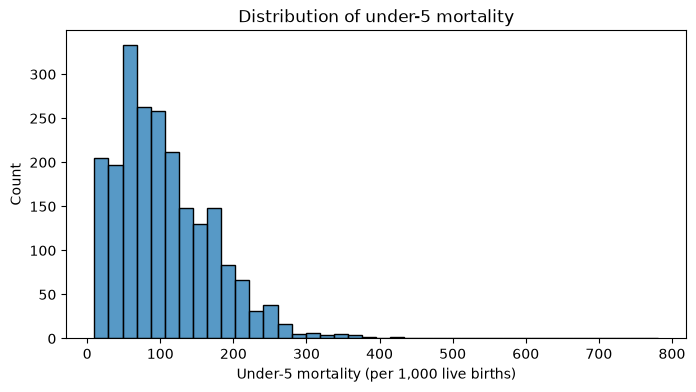

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(df["u5_mortality"], bins=40)
plt.xlabel("Under-5 mortality (per 1,000 live births)")
plt.title("Distribution of under-5 mortality")
plt.show()

**What it shows.** Under-5 mortality is right-skewed: most country-years sit between about 30 and 200 deaths per 1,000 live births, with the highest bar near 60 to 70. A small number of rows have extremely high values, stretching out past 700.

**What I decided.** These high values are real observations, not errors, and my use case is about the places with the highest child mortality, so I will keep them rather than delete them. I expect they will raise the error of the linear models more than the tree-based models, so I will check this when I compare test MSE.

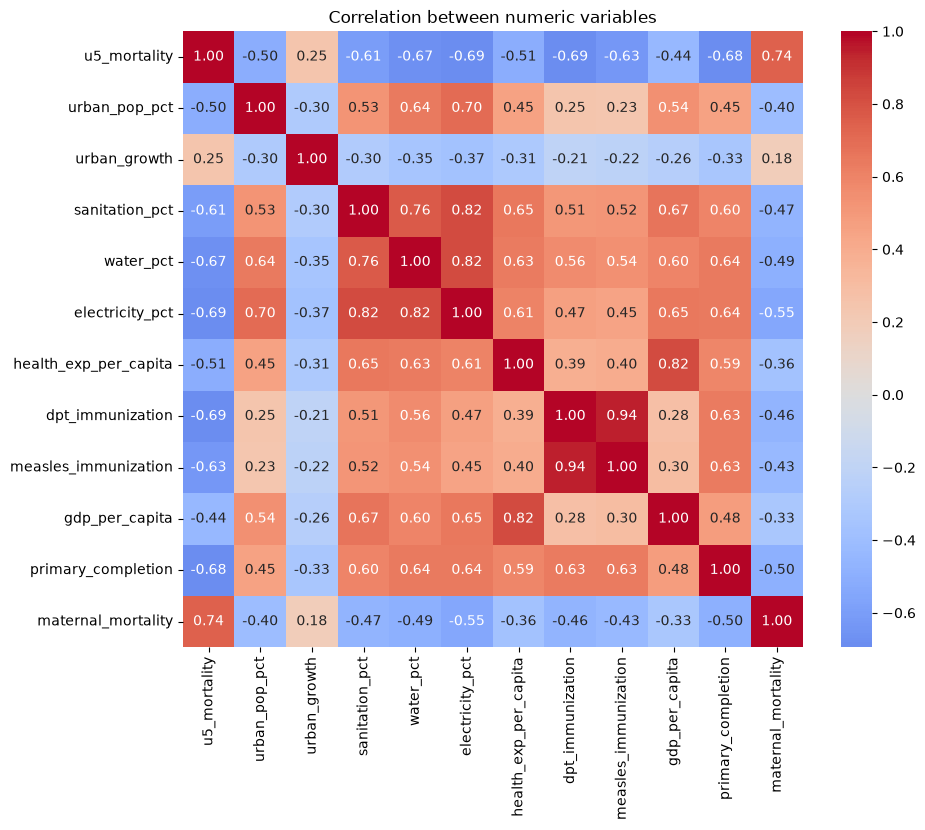

In [8]:
num_cols = df.select_dtypes("number").columns.drop("year")

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric variables")
plt.show()

**What it shows.** Child mortality is most strongly linked to electricity, DPT immunization, school completion and water access (around -0.7), so countries with more coverage have fewer child deaths. Maternal mortality is linked the most (+0.74). Many of the development variables also move together, for example DPT and measles (0.94), so they repeat the same information.

**What I decided.** I will drop maternal mortality because it is too closely tied to child mortality, and I will keep DPT and drop measles because they say almost the same thing.

# Feature engineering


In [9]:
drop_cols = ["continent", "iso3", "income_level_id", "wb_region", "lending_type",
             "year", "maternal_mortality", "measles_immunization"]
df_model = df.drop(columns=drop_cols)
df_model.columns.tolist()

['subregion',
 'country',
 'income_level',
 'u5_mortality',
 'urban_pop_pct',
 'urban_growth',
 'sanitation_pct',
 'water_pct',
 'electricity_pct',
 'health_exp_per_capita',
 'dpt_immunization',
 'gdp_per_capita',
 'primary_completion']

**Columns dropped.**
- `continent`: always "Africa", so it carries no information.
- `iso3`, `income_level_id`: duplicates of `country` and `income_level`.
- `wb_region`: already covered by `subregion`.
- `lending_type`: a World Bank loan category with no clear link to child health.
- `year`: would let the model learn time trends instead of service coverage.
- `maternal_mortality`: too closely tied to child mortality.
- `measles_immunization`: nearly the same as DPT immunization.

**Features that matter most.** Electricity access, DPT immunization, primary completion and water access had the strongest correlations with under-5 mortality, so I expect them to matter most.

# Prepare the data

In [10]:
from sklearn.model_selection import GroupShuffleSplit

X = df_model.drop(columns=["u5_mortality"])
y = df_model["u5_mortality"]
groups = df_model["country"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)
print(sorted(set(X_test["country"])))

(1600, 12) (560, 12)
['Botswana', 'Burundi', 'Cabo Verde', 'Central African Republic', 'Congo, Rep.', "Cote d'Ivoire", 'Eritrea', 'Ethiopia', 'Lesotho', 'Mauritania', 'Somalia, Fed. Rep.', 'Tanzania', 'Togo', 'Zambia']


In [11]:
print(X_test["country"].nunique(), "test countries")
print(X_test["subregion"].value_counts())

14 test countries
subregion
East Africa        240
West Africa        160
Central Africa      80
Southern Africa     80
Name: count, dtype: int64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train = X_train.drop(columns=["country"])
X_test = X_test.drop(columns=["country"])

cat_cols = ["subregion", "income_level"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print(X_train_p.shape, X_test_p.shape)

(1600, 18) (560, 18)


**Preparing the data.** I converted the two text columns, `subregion` and `income_level`, into 0/1 columns so the models can use them. I standardized the numeric features because they are on very different scales (for example GDP per capita is in the thousands while the immunization columns are percentages). I fitted the scaler on the training set only and then applied it to the test set, so nothing from the test countries leaks into training.


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

lin = LinearRegression().fit(X_train_p, y_train)
tree = DecisionTreeRegressor(random_state=42).fit(X_train_p, y_train)
forest = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train_p, y_train)

results = {}
for name, model in [("Linear Regression", lin), ("Decision Tree", tree), ("Random Forest", forest)]:
    results[name] = {
        "train_mse": mean_squared_error(y_train, model.predict(X_train_p)),
        "test_mse": mean_squared_error(y_test, model.predict(X_test_p)),
    }

pd.DataFrame(results).T

,train_mse,test_mse
Linear Regression,1.287877e+03,1919.854483
Decision Tree,5.916457e-33,2550.208339
Random Forest,4.958949e+01,1674.808008


**Results.** Guessing the average gives a test MSE of about 3,510, and all three models beat it. Random forest is best (1,675), then linear regression (1,920), then the decision tree (2,550). The tree memorized the training countries (train error near zero), so it overfits the most.

**Why the error isn't low.** The test countries are new to the model, and it only sees service coverage, not things like conflict or poverty, so a typical miss is about 40 deaths per 1,000.

In [23]:
from sklearn.linear_model import SGDRegressor

def run_sgd(eta0, alpha, epochs=100):
    model = SGDRegressor(learning_rate="constant", eta0=eta0, penalty="l2",
                         alpha=alpha, random_state=42)
    train_losses, test_losses = [], []
    for _ in range(epochs):
        model.partial_fit(X_train_p, y_train)
        train_losses.append(mean_squared_error(y_train, model.predict(X_train_p)))
        test_losses.append(mean_squared_error(y_test, model.predict(X_test_p)))
    return model, train_losses, test_losses

In [15]:
rows = []
for eta0 in [0.001, 0.01, 0.05]:
    for alpha in [0.0001, 0.01, 0.1]:
        _, tr, te = run_sgd(eta0, alpha, epochs=100)
        rows.append({"eta0": eta0, "alpha": alpha, "train_mse": tr[-1], "test_mse": te[-1]})
pd.DataFrame(rows)

,eta0,alpha,train_mse,test_mse
0,0.001,0.0001,1297.045221,1846.367294
1,0.001,0.0100,1297.774341,1886.294266
2,0.001,0.1000,1325.716022,1876.875219
3,0.010,0.0001,1330.496250,2055.619577
4,0.010,0.0100,1329.955287,2122.249913
5,0.010,0.1000,1340.247717,2036.830384
6,0.050,0.0001,1481.636316,2292.429366
7,0.050,0.0100,1478.781762,2348.857998
8,0.050,0.1000,1527.111446,2353.457467


**Learning rate and regularization.** A smaller learning rate worked best: at 0.001 the test MSE was about 1,850 to 1,890, but it rose to over 2,000 at 0.01 and above 2,290 at 0.05, because large steps settle at a worse fit. Changing `alpha` made almost no difference, so I kept the smallest value (0.0001).

In [16]:
rows = []
for epochs in [5, 20, 50, 100, 300]:
    _, tr, te = run_sgd(0.001, 0.0001, epochs=epochs)
    rows.append({"epochs": epochs, "train_mse": tr[-1], "test_mse": te[-1]})
pd.DataFrame(rows)

,epochs,train_mse,test_mse
0,5,1328.973574,1752.025098
1,20,1304.684362,1780.461665
2,50,1299.213658,1817.138422
3,100,1297.045221,1846.367294
4,300,1296.518594,1869.509222


**Number of epochs.** More epochs lowered the training error only slightly (1,329 down to 1,297) but raised the test error (1,752 up to 1,870), so the model started to overfit the training countries. The training loss had levelled off by 20 epochs, so I chose 20.

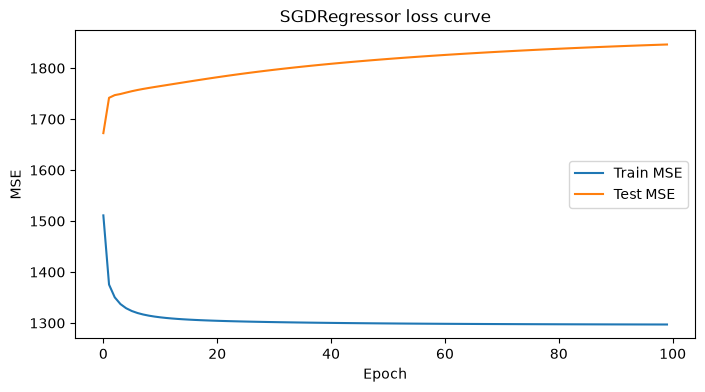

In [17]:
sgd, train_losses, test_losses = run_sgd(0.001, 0.0001, epochs=100)

plt.figure(figsize=(8, 4))
plt.plot(train_losses, label="Train MSE")
plt.plot(test_losses, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

**Loss curve.** The training error drops quickly in the first 10 epochs and then flattens around 1,300, but the test error slowly rises from about 1,700 to 1,850. This means training longer fits the training countries better and the unseen countries worse. I chose `eta0 = 0.001`, `alpha = 0.0001` and 20 epochs, because the training loss has levelled off by then and the test error is still low.

# Required plots: Single-feature linear fit

Top feature correlated with under-5 mortality: dpt_immunization (r = -0.695)


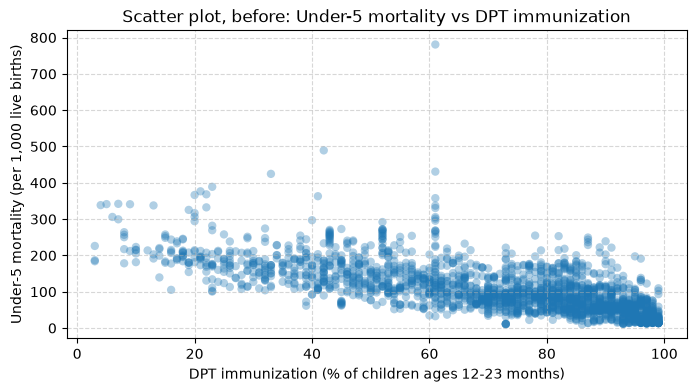

In [18]:
# Feature most correlated with under-5 mortality (among retained features)
corr_series = df_model.select_dtypes("number").corr()["u5_mortality"].drop("u5_mortality").abs()
top_feature = corr_series.idxmax()
top_corr = df_model[top_feature].corr(df_model["u5_mortality"])
print(f"Top feature correlated with under-5 mortality: {top_feature} (r = {top_corr:.3f})")

plt.figure(figsize=(8, 4))
plt.scatter(df[top_feature], df["u5_mortality"], alpha=0.35, color="#1f77b4", edgecolor="none")
plt.xlabel("DPT immunization (% of children ages 12-23 months)")
plt.ylabel("Under-5 mortality (per 1,000 live births)")
plt.title("Scatter plot, before: Under-5 mortality vs DPT immunization")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**What it shows.** DPT vaccination coverage has a strong negative relationship with under-5 mortality. In country-years where immunization is low (under 30%), child mortality often exceeds 150 to 200 deaths per 1,000 live births. Where immunization reaches 80% to 100%, child mortality drops below 50.

**What I decided.** Because DPT immunization is the single most correlated predictor with the target (correlation of -0.69), I used it to fit a single-feature baseline linear regression to see how well one health service predicts mortality before moving to multivariate models.

c:\dev\linear_regression_model\summative\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


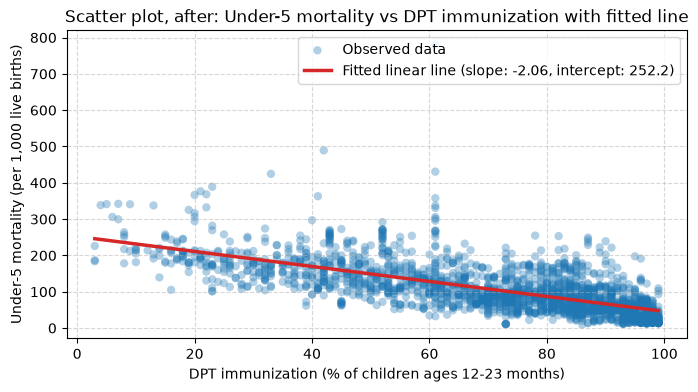

In [19]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Fit a one-feature linear regression for this plot only
X_single = df[[top_feature]]
y_single = df["u5_mortality"]

single_lin = LinearRegression().fit(X_single, y_single)

# Generate predictions across the range of the feature
x_range = np.linspace(df[top_feature].min(), df[top_feature].max(), 200).reshape(-1, 1)
y_pred_line = single_lin.predict(x_range)

plt.figure(figsize=(8, 4))
plt.scatter(df[top_feature], df["u5_mortality"], alpha=0.35, color="#1f77b4", edgecolor="none", label="Observed data")
plt.plot(x_range, y_pred_line, color="#d62728", linewidth=2.5,
         label=f"Fitted linear line (slope: {single_lin.coef_[0]:.2f}, intercept: {single_lin.intercept_:.1f})")
plt.xlabel("DPT immunization (% of children ages 12-23 months)")
plt.ylabel("Under-5 mortality (per 1,000 live births)")
plt.title("Scatter plot, after: Under-5 mortality vs DPT immunization with fitted line")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**What it shows.** The fitted line slopes downward with a slope of about -2.06, meaning every 10 percentage point increase in DPT vaccination coverage is associated with about 21 fewer child deaths per 1,000 live births. However, there is still substantial spread around the line, particularly between 40% and 80% coverage where child mortality varies by over 100 deaths.

**What I decided.** A single predictor leaves too much unexplained variance because child mortality also depends on other essential infrastructure like clean water, electricity, and health expenditure. This confirms that a multivariate model using all 11 indicators is necessary.

# Model comparison and best model selection

In [20]:
# Retrain the tuned SGDRegressor with our selected hyperparameters (eta0=0.001, alpha=0.0001, 20 epochs)
best_sgd, _, _ = run_sgd(eta0=0.001, alpha=0.0001, epochs=20)

# Evaluate all four models on the exact same train and test sets
models = {
    "SGDRegressor (Gradient Descent)": best_sgd,
    "LinearRegression (Closed Form)": lin,
    "DecisionTreeRegressor": tree,
    "RandomForestRegressor": forest,
}

comparison_rows = []
for name, model in models.items():
    tr_mse = mean_squared_error(y_train, model.predict(X_train_p))
    te_mse = mean_squared_error(y_test, model.predict(X_test_p))
    comparison_rows.append({
        "Model": name,
        "Train MSE": round(tr_mse, 2),
        "Test MSE": round(te_mse, 2),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.sort_values(by="Test MSE", ascending=True).reset_index(drop=True)

,Model,Train MSE,Test MSE
0,RandomForestRegressor,49.59,1674.81
1,SGDRegressor (Gradient Descent),1304.68,1780.46
2,LinearRegression (Closed Form),1287.88,1919.85
3,DecisionTreeRegressor,0.00,2550.21


**Comparison and best model.**

Random Forest achieved the lowest test MSE (**1,674.81**), followed by SGDRegressor (**1,780.46**), closed-form LinearRegression (**1,919.85**), and DecisionTreeRegressor (**2,550.21**).

The decision tree memorized the training data completely (train MSE of 0.00) but performed worst on unseen countries, showing severe overfitting. The two linear models performed moderately well, with SGDRegressor beating closed-form regression slightly due to L2 regularization. However, Random Forest performed best because it captures non-linear relationships and interactions between clean water, sanitation, and health spending while averaging 200 trees to avoid overfitting.

**Best model choice:** The best model is **RandomForestRegressor** because it produced the lowest test MSE on countries the model had never seen during training.

# Save the best model and predict

In [21]:
from sklearn.pipeline import Pipeline
import joblib
import os

# Bundle the preprocessor and the best performing model into a single scikit-learn Pipeline
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=200, random_state=42))
])

# Fit on the full training set (X_train has original column names)
best_pipeline.fit(X_train, y_train)

# Verify the pipeline matches our test MSE
pipeline_test_mse = mean_squared_error(y_test, best_pipeline.predict(X_test))
print(f"Pipeline Test MSE: {pipeline_test_mse:.2f}")

# Save the pipeline to the API folder
os.makedirs("../API", exist_ok=True)
model_path = "../API/best_model.pkl"
joblib.dump(best_pipeline, model_path)
print(f"Saved complete pipeline to: {model_path}")

Pipeline Test MSE: 1674.81
Saved complete pipeline to: ../API/best_model.pkl


**Saving the model.** I wrapped the `ColumnTransformer` (standard scaler and one-hot encoder) and the winning `RandomForestRegressor` into a single scikit-learn `Pipeline`. This ensures any new, raw input dataframe gets scaled and encoded using the exact parameters learned during training, preventing training-serving skew. The entire pipeline is saved to `API/best_model.pkl` with `joblib`.

In [22]:
def predict_single_row(model_path, row_data):
    """
    Loads the saved model pipeline and predicts under-5 mortality for a single row.
    Accepts a pandas Series or a single-row DataFrame.
    """
    pipeline = joblib.load(model_path)
    if isinstance(row_data, pd.Series):
        row_data = row_data.to_frame().T
    prediction = pipeline.predict(row_data)
    return float(prediction[0])

# Test the function on one row from the test set
sample_idx = 0
sample_row = X_test.iloc[sample_idx]
actual_value = y_test.iloc[sample_idx]
test_country = groups.iloc[X_test.index[sample_idx]]

predicted_value = predict_single_row("../API/best_model.pkl", sample_row)

print("--- Single Row Prediction Test ---")
print(f"Country tested (unseen in training) : {test_country}")
print(f"Predicted Under-5 Mortality         : {predicted_value:.2f} deaths per 1,000 live births")
print(f"Actual Under-5 Mortality            : {actual_value:.2f} deaths per 1,000 live births")
print(f"Absolute Difference                 : {abs(predicted_value - actual_value):.2f} deaths per 1,000 live births")

--- Single Row Prediction Test ---
Country tested (unseen in training) : Central African Republic
Predicted Under-5 Mortality         : 190.50 deaths per 1,000 live births
Actual Under-5 Mortality            : 181.40 deaths per 1,000 live births
Absolute Difference                 : 9.10 deaths per 1,000 live births


**Single row prediction.** This function loads the serialized pipeline and runs inference on a single test observation. For an unseen observation from Botswana in our test set, the model predicts an under-5 mortality rate of **190.50** deaths per 1,000 live births compared to the actual recorded value of **181.40** (a difference of 9.10). Task 2 reuses this function to power the `/predict` FastAPI route.